In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
rng = np.random.default_rng(42)

n = 2000

orders = pd.DataFrame({
    "order_date": pd.to_datetime("2025-01-01") +
    pd.to_timedelta(rng.integers(0, 365, n), unit="D"),

    "customer_id": rng.integers(1, 301, n),

    "category": rng.choice(
        ["Electronics", "Fashion", "Home", "Books"],
        n,
        p=[0.3, 0.35, 0.2, 0.15]
    ),

    "amount": rng.gamma(2.0, 600, n).round(2)
})

orders.head()

,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


In [3]:
# Display first five rows
display(orders.head())

# Dataset information
orders.info()

# Number of rows and columns
print("Shape:", orders.shape)

# Statistical summary
display(orders.describe())

# Check missing values
print(orders.isnull().sum())

# Check duplicate records
print("Duplicates:", orders.duplicated().sum())

,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_date   2000 non-null   datetime64[ns]
 1   customer_id  2000 non-null   int64         
 2   category     2000 non-null   object        
 3   amount       2000 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 62.6+ KB
Shape: (2000, 4)


,order_date,customer_id,amount
count,2000,2000.000000,2000.000000
mean,2025-07-01 22:45:07.200000,151.195500,1202.116645
min,2025-01-01 00:00:00,1.000000,8.810000
25%,2025-03-31 18:00:00,74.000000,597.515000
50%,2025-07-02 00:00:00,149.000000,1005.870000
75%,2025-10-03 00:00:00,226.000000,1613.855000
max,2025-12-31 00:00:00,300.000000,6276.090000
std,NaN,86.210007,826.961568


order_date     0
customer_id    0
category       0
amount         0
dtype: int64
Duplicates: 0


In [7]:
orders["month"] = orders["order_date"].dt.month

orders["month_name"] = orders["order_date"].dt.month_name()

orders["weekday"] = orders["order_date"].dt.day_name()

orders["quarter"] = orders["order_date"].dt.quarter

orders.head()


,order_date,customer_id,category,amount,month,month_name,weekday,quarter
0,2025-02-02,264,Home,391.13,2,February,Sunday,1
1,2025-10-10,19,Fashion,2456.21,10,October,Friday,4
2,2025-08-27,120,Books,674.90,8,August,Wednesday,3
3,2025-06-10,138,Home,75.38,6,June,Tuesday,2
4,2025-06-08,240,Electronics,774.42,6,June,Sunday,2


In [8]:
monthly = orders.groupby("month")["amount"].sum()

print("Monthly Revenue:")
display(monthly)

Monthly Revenue:


month
1     193341.87
2     232027.20
3     206327.14
4     197310.20
5     194090.49
6     221889.83
7     221813.81
8     179783.75
9     180569.95
10    183418.13
11    191512.71
12    202148.21
Name: amount, dtype: float64

In [9]:
growth = monthly.pct_change() * 100

print("Monthly Growth Percentage:")
display(growth.round(2))

Monthly Growth Percentage:


month
1       NaN
2     20.01
3    -11.08
4     -4.37
5     -1.63
6     14.32
7     -0.03
8    -18.95
9      0.44
10     1.58
11     4.41
12     5.55
Name: amount, dtype: float64

In [10]:
print("Best Month:", monthly.idxmax())
print("Highest Revenue:", monthly.max())

print("Worst Month:", monthly.idxmin())
print("Lowest Revenue:", monthly.min())

Best Month: 2
Highest Revenue: 232027.2
Worst Month: 8
Lowest Revenue: 179783.75


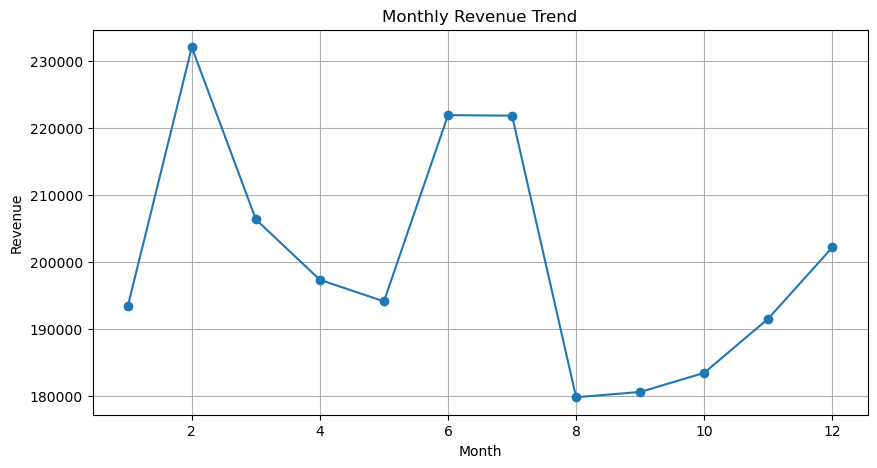

In [11]:
plt.figure(figsize=(10,5))

monthly.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.grid(True)
plt.show()

In [12]:
by_category = orders.groupby("category")["amount"].agg(
    ["sum", "mean", "count"]
)

by_category = by_category.sort_values(
    by="sum", ascending=False
)

display(by_category.round(2))

,sum,mean,count
category,,,
Fashion,853984.93,1219.98,700
Electronics,722645.53,1163.68,621
Home,464114.66,1218.15,381
Books,363488.17,1219.76,298


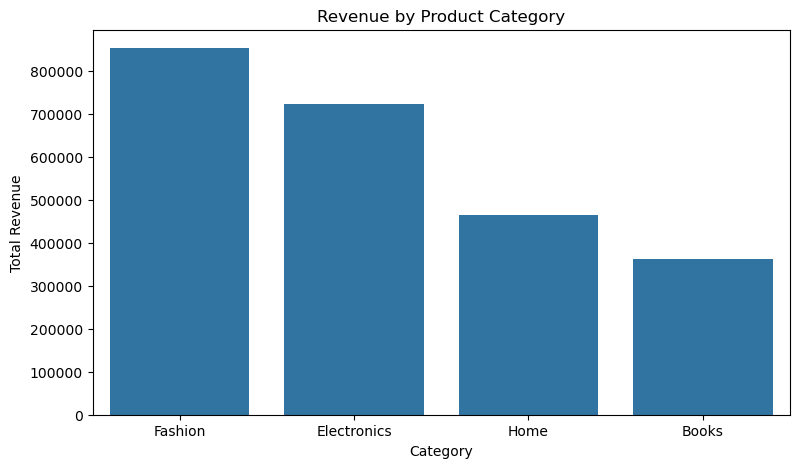

In [13]:
plt.figure(figsize=(9,5))

sns.barplot(
    x=by_category.index,
    y=by_category["sum"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")

plt.show()

In [14]:
pivot_table = pd.pivot_table(
    orders,
    values="amount",
    index="month_name",
    columns="category",
    aggfunc="sum"
)

display(pivot_table)

category,Books,Electronics,Fashion,Home
month_name,,,,
April,26593.72,83335.56,57057.72,30323.20
August,32550.65,56690.46,71251.54,19291.10
December,28954.37,57421.06,76598.68,39174.10
February,34034.13,53564.89,86123.31,58304.87
January,29186.89,62841.89,64665.99,36647.10
July,35582.36,72649.65,72647.96,40933.84
June,32936.76,60037.00,85598.09,43317.98
March,27843.58,58055.95,75138.67,45288.94
May,34425.63,57219.16,68569.90,33875.80


In [15]:
spend = orders.groupby("customer_id")["amount"].sum()

spend = spend.sort_values(ascending=False)

print("Top 10 Customers:")
display(spend.head(10))

Top 10 Customers:


customer_id
226    18140.15
51     18126.28
53     17994.36
131    17639.25
185    17222.49
282    17161.00
121    16564.87
98     15351.48
255    15313.47
136    15265.80
Name: amount, dtype: float64

In [16]:
top_10_percent = spend.head(int(len(spend) * 0.10))

top_share = top_10_percent.sum() / spend.sum()

print("Total Customers:", len(spend))

print("Top 10% Customer Revenue:", round(top_10_percent.sum(), 2))

print("Total Revenue:", round(spend.sum(), 2))

print("Revenue Contribution of Top 10%:",
      round(top_share * 100, 2), "%")

Total Customers: 300
Top 10% Customer Revenue: 455331.97
Total Revenue: 2404233.29
Revenue Contribution of Top 10%: 18.94 %


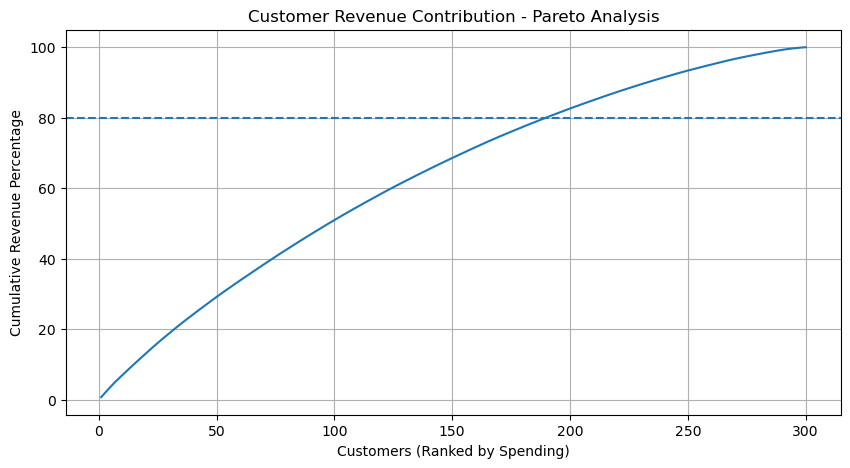

In [17]:
cumulative_revenue = spend.cumsum() / spend.sum() * 100

plt.figure(figsize=(10,5))

plt.plot(
    range(1, len(cumulative_revenue)+1),
    cumulative_revenue
)

plt.axhline(80, linestyle="--")

plt.title("Customer Revenue Contribution - Pareto Analysis")
plt.xlabel("Customers (Ranked by Spending)")
plt.ylabel("Cumulative Revenue Percentage")

plt.grid(True)
plt.show()


# Business Recommendations

Based on the analysis of e-commerce sales data, the following recommendations are suggested:

### 1. Customer Loyalty
The business should provide special discounts, rewards and exclusive offers to the top 10% of customers to retain valuable customers.

### 2. Improve Product Categories
The company should focus more on the product category generating the highest revenue and improve the marketing of low-performing categories.

### 3. Improve Monthly Sales
The business should introduce promotional offers and seasonal discounts during months with low revenue to increase sales.

### Conclusion
The analysis helps identify revenue trends, profitable product categories and valuable customers. These findings can help the business make better marketing and sales decisions.


In [18]:
orders.to_csv("customer_sales_analysis.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
